In [28]:
import pandas as pd
spectraverse_spec_df = pd.read_pickle('../../data/proc/spectraverse/spec_df.pkl')
spectraverse_spec_df

,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,res,ace,nce,prec_mz,peaks,ri,group_id
0,0,30673,[M-H]-,Other,CID,MS2,NaN,spectraverse,0,NaN,5,9.643298,NaN,241.082447,"[(125.03542, 1.0), (151.0509, 0.68447260568509...",NaN,0
1,1,35067,[M-H]-,Other,CID,MS2,NaN,spectraverse,1,NaN,5,4.600125,NaN,115.003134,"[(71.01382, 0.41149826778021587), (115.00361, ...",NaN,1
2,2,32322,[M-H]-,Other,CID,MS2,NaN,spectraverse,3,NaN,5,5.802453,NaN,145.061317,"[(84.0457, 0.003689695000889696), (109.04069, ...",NaN,2
3,3,3723,[M-H]-,Other,CID,MS2,NaN,spectraverse,5,NaN,5,7.805208,NaN,130.086804,"[(84.08231, 0.7870069320900558), (130.08693, 1...",NaN,3
4,4,2997,[M-H]-,Other,CID,MS2,NaN,spectraverse,6,NaN,4,8.724114,NaN,218.102848,"[(88.0402, 0.38402328466943453), (146.0816, 0....",NaN,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
374241,374241,6644,[M+H]+,Other,CID,MS2,NaN,spectraverse,150208,NaN,4,17.906970,NaN,179.0697,"[(114.0907, 0.00579847), (115.0537, 0.04745281...",NaN,69101
374242,374242,6644,[M+H]+,Other,CID,MS2,NaN,spectraverse,150209,NaN,4,12.534879,NaN,179.0697,"[(115.0532, 0.01348332), (116.1062, 1.0), (117...",NaN,69101
374243,374243,6644,[M+H]+,Other,CID,MS2,NaN,spectraverse,150212,NaN,4,3.581394,NaN,179.0697,"[(116.1064, 0.07511868), (117.1095, 0.00538161...",NaN,69101
374244,374244,24442,[M-H]-,NaN,CID,MS2,NaN,spectraverse,929,NaN,4,30.000000,NaN,223.06084,"[(58.0641, 0.008839320000000001), (70.064, 0.0...",NaN,1278


In [29]:
#spectraverse_spec_df['ace'] = spectraverse_spec_df.apply(lambda x: round(x['prec_mz'] * x['nce'] / 500, 0), axis=1)

In [30]:
# Group by prec_type (adducts) and count the number of spectra in each group
adduct_counts = spectraverse_spec_df['prec_type'].value_counts().sort_values(ascending=False)
# Display the results
print(f"Number of unique adduct types: {len(adduct_counts)}")
print("\nTop adduct types:\n")
print(adduct_counts)

Number of unique adduct types: 9

Top adduct types:

prec_type
[M+H]+          172878
[M-H]-           77874
[M+Na]+          69518
[M+NH4]+         19789
[M+CH2O2-H]-     15101
[M+Cl]-           6512
[M+CH3COO]-       6266
[M+K]+            4364
[M]+              1944
Name: count, dtype: int64


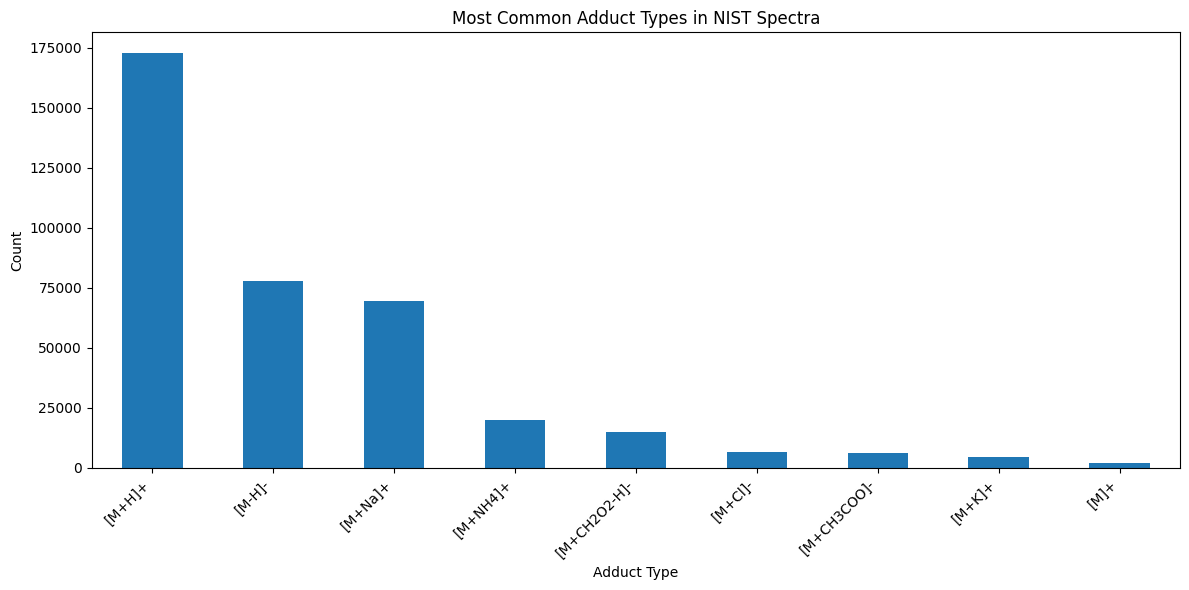

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
adduct_counts.head(50).plot(kind='bar')
plt.title('Most Common Adduct Types in NIST Spectra')
plt.ylabel('Count')
plt.xlabel('Adduct Type')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [32]:
spectraverse_mol_df = pd.read_pickle('../../data/proc/spectraverse/mol_df.pkl')
spectraverse_mol_df.head()

,smiles,mol_id,mol,inchikey_s,scaffold,formula,inchi,mw,exact_mw,num_atoms,num_bonds,charge,single_mol,num_radicals
0,Brc1c(Br)c(Br)c2[nH]nnc2c1Br,0,<rdkit.Chem.rdchem.Mol object at 0x7f28b801ba60>,OMZYUVOATZSGJY,c1ccc2[nH]nnc2c1,C6HBr4N3,InChI=1S/C6HBr4N3/c7-1-2(8)4(10)6-5(3(1)9)11-1...,434.711,430.690395,13,14,0,True,0
1,Brc1c(NC2=NCCN2)ccc2nccnc12,1,<rdkit.Chem.rdchem.Mol object at 0x7f28b8019a30>,XYLJNLCSTIOKRM,c1cnc2cc(NC3=NCCN3)ccc2n1,C11H10BrN5,InChI=1S/C11H10BrN5/c12-9-7(17-11-15-5-6-16-11...,292.140,291.011957,17,19,0,True,0
2,Brc1cc(-c2ccccn2)nc(-c2ccccn2)c1,2,<rdkit.Chem.rdchem.Mol object at 0x7f28b801ad40>,CJRRILXBSCRHKN,c1ccc(-c2cccc(-c3ccccn3)n2)nc1,C15H10BrN3,InChI=1S/C15H10BrN3/c16-11-9-14(12-5-1-3-7-17-...,312.170,311.005809,19,21,0,True,0
3,Brc1cc2c(cc1C1Nc3ccccc3C3C=CCC31)OCO2,3,<rdkit.Chem.rdchem.Mol object at 0x7f28b8019170>,YOLTZIVRJAPVPH,C1=CC2c3ccccc3NC(c3ccc4c(c3)OCO4)C2C1,C19H16BrNO2,InChI=1S/C19H16BrNO2/c20-15-9-18-17(22-10-23-1...,370.246,369.036441,23,27,0,True,0
4,Brc1cc2c(cc1C=Nc1c(-c3ccco3)nc3ccccn13)OCO2,4,<rdkit.Chem.rdchem.Mol object at 0x7f28b8019940>,DVOYQGQPGICUKP,C(=Nc1c(-c2ccco2)nc2ccccn12)c1ccc2c(c1)OCO2,C19H12BrN3O3,InChI=1S/C19H12BrN3O3/c20-13-9-16-15(25-11-26-...,410.227,409.006203,26,30,0,True,0


In [33]:
spectraverse_mol_df.iloc[0]

smiles                               Brc1c(Br)c(Br)c2[nH]nnc2c1Br
mol_id                                                          0
mol              <rdkit.Chem.rdchem.Mol object at 0x7f28b801ba60>
inchikey_s                                         OMZYUVOATZSGJY
scaffold                                         c1ccc2[nH]nnc2c1
formula                                                  C6HBr4N3
inchi           InChI=1S/C6HBr4N3/c7-1-2(8)4(10)6-5(3(1)9)11-1...
mw                                                        434.711
exact_mw                                               430.690395
num_atoms                                                      13
num_bonds                                                      14
charge                                                          0
single_mol                                                   True
num_radicals                                                    0
Name: 0, dtype: object

In [34]:
spectraverse_df = spectraverse_spec_df.merge(spectraverse_mol_df, on='mol_id', how='left')

spectraverse_df.head()

,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,...,scaffold,formula,inchi,mw,exact_mw,num_atoms,num_bonds,charge,single_mol,num_radicals
0,0,30673,[M-H]-,Other,CID,MS2,NaN,spectraverse,0,NaN,...,O=c1ccn(C2CCCO2)c(=O)[nH]1,C10H14N2O5,InChI=1S/C10H14N2O5/c1-5-3-12(10(16)11-9(5)15)...,242.231,242.090272,17,18,0,True,0
1,1,35067,[M-H]-,Other,CID,MS2,NaN,spectraverse,1,NaN,...,,C4H4O4,"InChI=1S/C4H4O4/c5-3(6)1-2-4(7)8/h1-2H,(H,5,6)...",116.072,116.010959,8,7,0,True,0
2,2,32322,[M-H]-,Other,CID,MS2,NaN,spectraverse,3,NaN,...,,C5H10N2O3,"InChI=1S/C5H10N2O3/c6-3(5(9)10)1-2-4(7)8/h3H,1...",146.146,146.069142,10,9,0,True,0
3,3,3723,[M-H]-,Other,CID,MS2,NaN,spectraverse,5,NaN,...,,C6H13NO2,"InChI=1S/C6H13NO2/c1-4(2)3-5(7)6(8)9/h4-5H,3,7...",131.175,131.094629,9,8,0,True,0
4,4,2997,[M-H]-,Other,CID,MS2,NaN,spectraverse,6,NaN,...,,C9H17NO5,"InChI=1S/C9H17NO5/c1-9(2,5-11)7(14)8(15)10-4-3...",219.237,219.110673,15,14,0,True,0


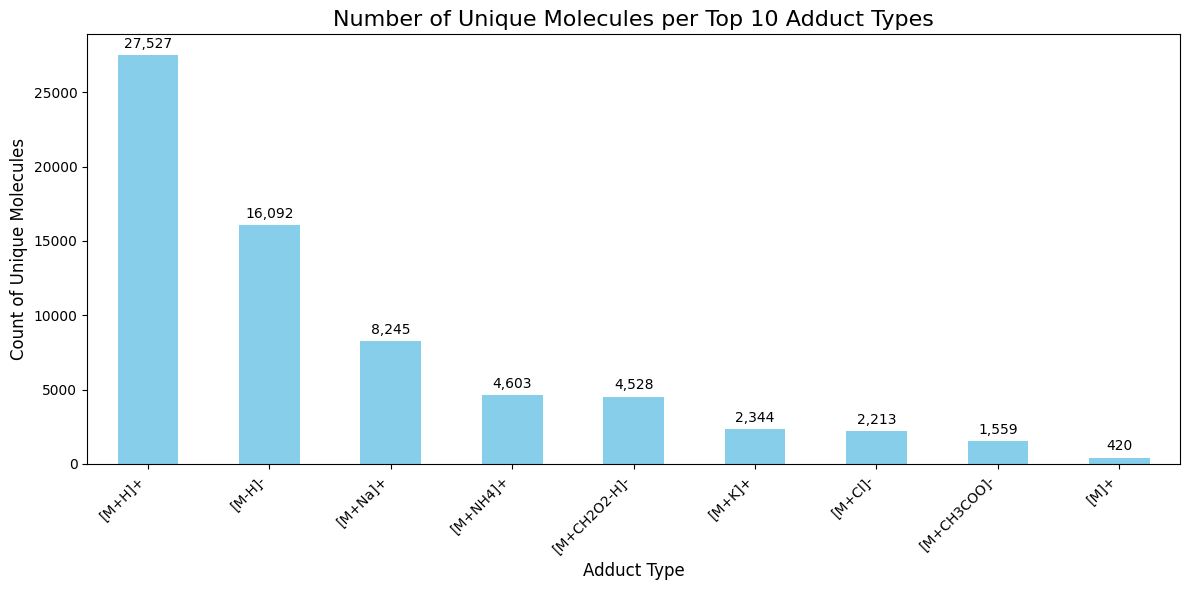

Number of unique molecules per adduct type:
prec_type
[M+H]+          27527
[M-H]-          16092
[M+Na]+          8245
[M+NH4]+         4603
[M+CH2O2-H]-     4528
[M+K]+           2344
[M+Cl]-          2213
[M+CH3COO]-      1559
[M]+              420
Name: mol_id, dtype: int64


In [35]:
# Calculate the number of unique molecules per each adduct type
unique_mols_per_adduct = spectraverse_df.groupby('prec_type')['mol_id'].nunique().sort_values(ascending=False)

# Get the top 10 adduct types by number of unique molecules
top_10_adducts_by_mols = unique_mols_per_adduct.head(10)

# Create a bar plot
plt.figure(figsize=(12, 6))
top_10_adducts_by_mols.plot(kind='bar', color='skyblue')

# Add labels and title
plt.title('Number of Unique Molecules per Top 10 Adduct Types', fontsize=16)
plt.xlabel('Adduct Type', fontsize=12)
plt.ylabel('Count of Unique Molecules', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Add value labels on top of each bar
for i, v in enumerate(top_10_adducts_by_mols):
    plt.text(i, v + 0.01*max(top_10_adducts_by_mols), f"{v:,}", 
             ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

# Print the counts as well
print("Number of unique molecules per adduct type:")
print(top_10_adducts_by_mols)

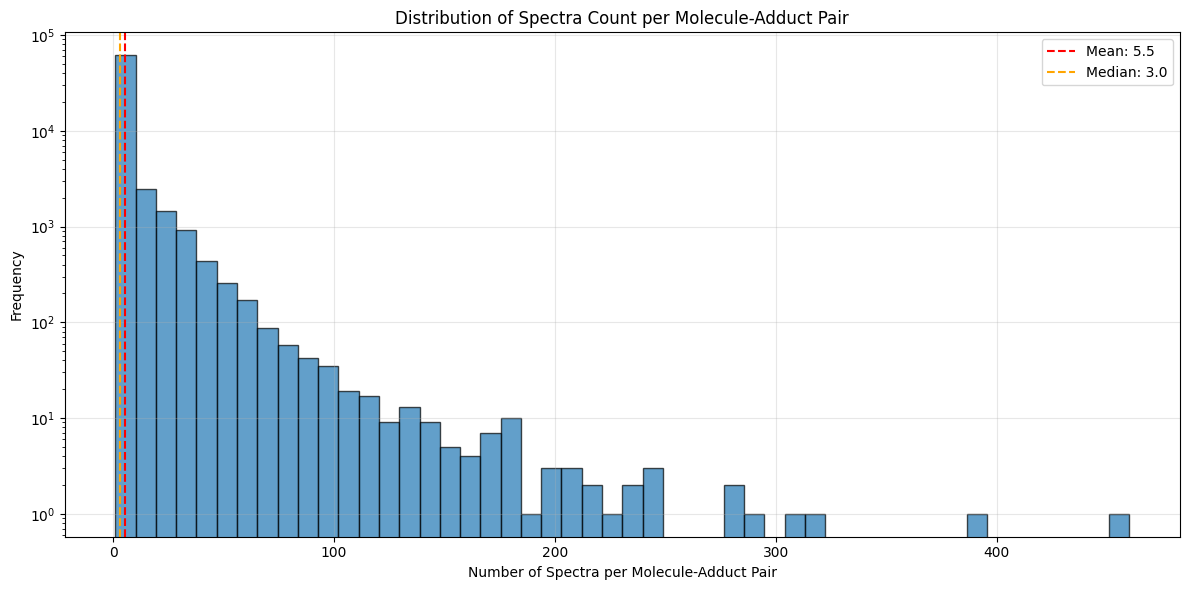

Total molecule-adduct pairs: 67,531
Mean spectra per pair: 5.54
Median spectra per pair: 3.00
Max spectra per pair: 460
Min spectra per pair: 1


In [36]:
# Calculate the number of spectra per molecule-adduct pair
spectra_per_mol_adduct = spectraverse_df.groupby(['mol_id', 'prec_type']).size()

# Create histogram
plt.figure(figsize=(12, 6))
plt.hist(spectra_per_mol_adduct, bins=50, edgecolor='black', alpha=0.7)
plt.xlabel('Number of Spectra per Molecule-Adduct Pair')
plt.ylabel('Frequency')
plt.title('Distribution of Spectra Count per Molecule-Adduct Pair')
plt.yscale('log')  # Use log scale for better visualization
plt.grid(True, alpha=0.3)

# Add some statistics
mean_spectra = spectra_per_mol_adduct.mean()
median_spectra = spectra_per_mol_adduct.median()
plt.axvline(mean_spectra, color='red', linestyle='--', label=f'Mean: {mean_spectra:.1f}')
plt.axvline(median_spectra, color='orange', linestyle='--', label=f'Median: {median_spectra:.1f}')
plt.legend()

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"Total molecule-adduct pairs: {len(spectra_per_mol_adduct):,}")
print(f"Mean spectra per pair: {mean_spectra:.2f}")
print(f"Median spectra per pair: {median_spectra:.2f}")
print(f"Max spectra per pair: {spectra_per_mol_adduct.max()}")
print(f"Min spectra per pair: {spectra_per_mol_adduct.min()}")

In [37]:
import ms_entropy as me
import numpy as np
from tqdm.notebook import tqdm

print("Calculating spectral entropy...")
#peaks_query = np.array(spectraverse_spec_df.iloc[0]['peaks'])
#me.calculate_spectral_entropy(peaks_query, clean_spectrum = True, min_ms2_difference_in_da = 0.05)

tqdm.pandas(desc="Processing")
spectraverse_spec_df['ms_entropy'] = spectraverse_spec_df['peaks'].progress_apply(
    lambda peaks: me.calculate_spectral_entropy(
        np.array(peaks), clean_spectrum=True, min_ms2_difference_in_da=0.05
    )
)

Calculating spectral entropy...


Processing:   0%|          | 0/374246 [00:00<?, ?it/s]

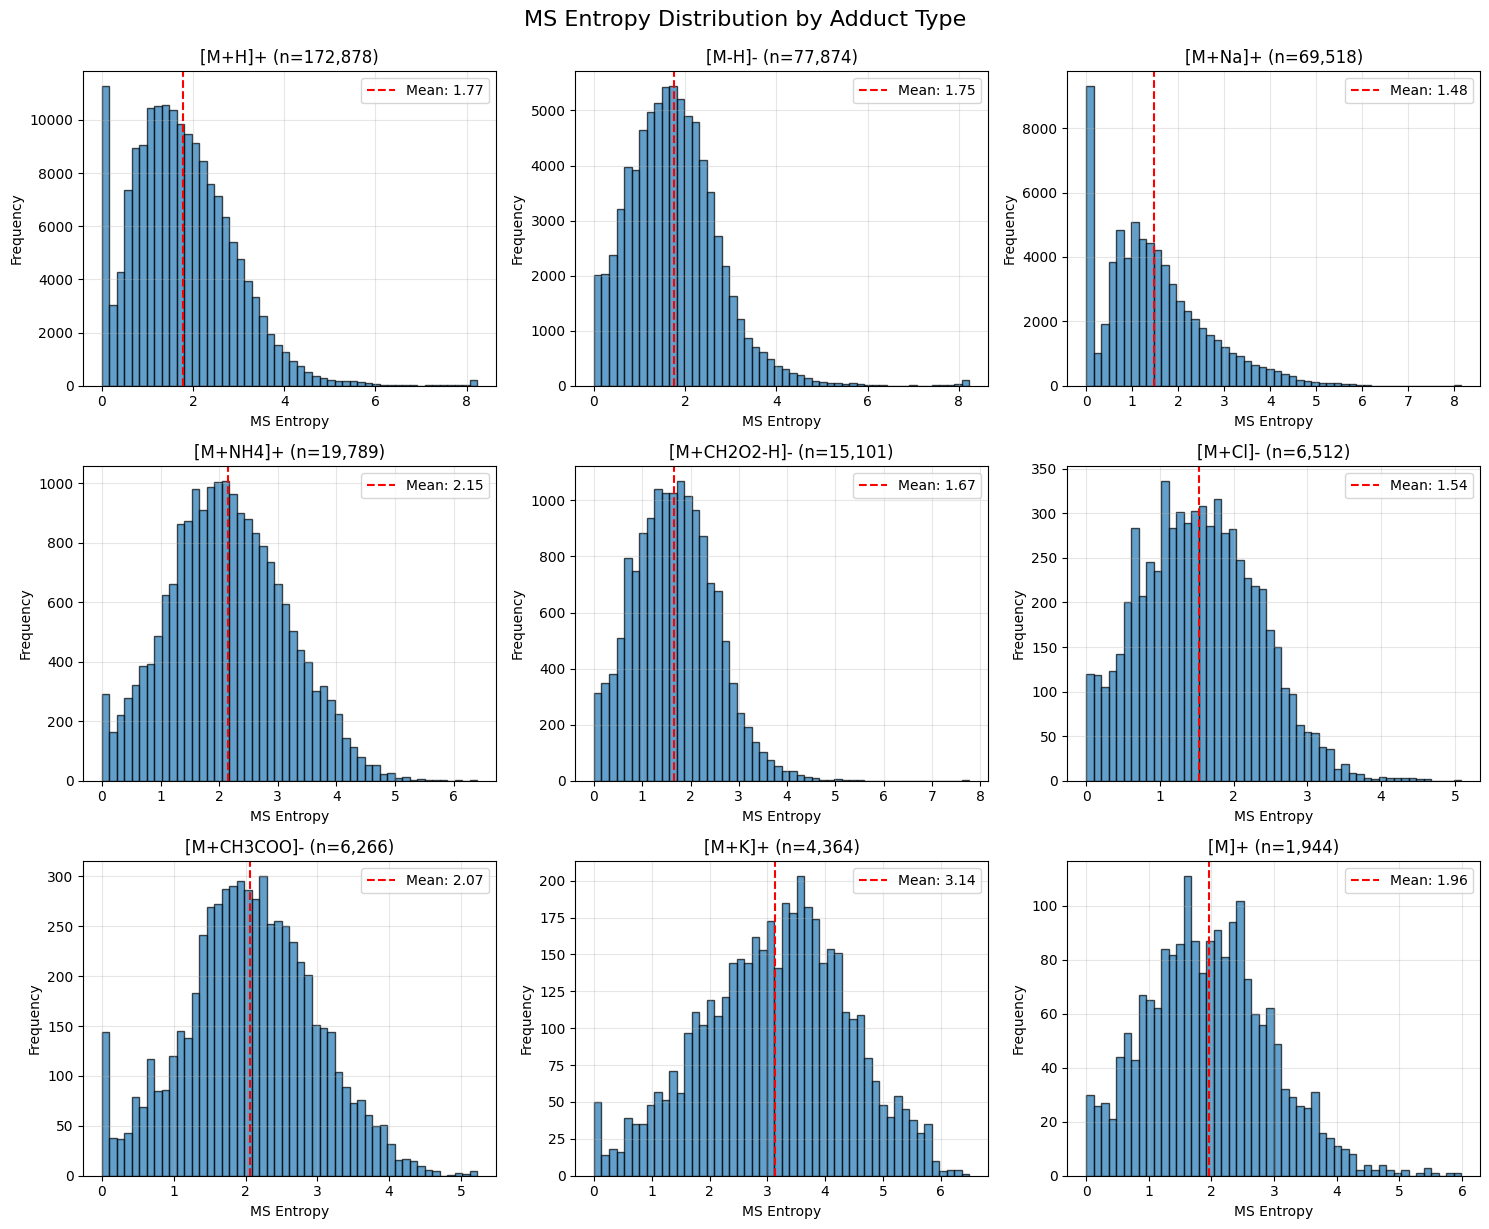

MS Entropy Statistics by Adduct Type:
--------------------------------------------------
[M+H]+      : Mean=1.769, Std=1.104, Median=1.657, Count=172,878
[M-H]-      : Mean=1.749, Std=0.987, Median=1.682, Count=77,874
[M+Na]+     : Mean=1.479, Std=1.110, Median=1.311, Count=69,518
[M+NH4]+    : Mean=2.147, Std=0.993, Median=2.105, Count=19,789
[M+CH2O2-H]-: Mean=1.668, Std=0.836, Median=1.644, Count=15,101
[M+Cl]-     : Mean=1.537, Std=0.786, Median=1.513, Count=6,512
[M+CH3COO]- : Mean=2.065, Std=0.913, Median=2.057, Count=6,266
[M+K]+      : Mean=3.135, Std=1.257, Median=3.225, Count=4,364
[M]+        : Mean=1.963, Std=0.979, Median=1.930, Count=1,944


In [38]:
# Create subplots for entropy distribution by adduct type
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

top_adducts = ['[M+H]+', '[M-H]-', '[M+Na]+', '[M+NH4]+', '[M+CH2O2-H]-', '[M+Cl]-', '[M+CH3COO]-', '[M+K]+', '[M]+']

for i, adduct in enumerate(top_adducts):
    adduct_data = spectraverse_spec_df[spectraverse_spec_df['prec_type'] == adduct]['ms_entropy']
    
    axes[i].hist(adduct_data, bins=50, alpha=0.7, edgecolor='black')
    axes[i].set_title(f'{adduct} (n={len(adduct_data):,})')
    axes[i].set_xlabel('MS Entropy')
    axes[i].set_ylabel('Frequency')
    axes[i].grid(True, alpha=0.3)
    
    # Add mean line
    mean_entropy = adduct_data.mean()
    axes[i].axvline(mean_entropy, color='red', linestyle='--', 
                   label=f'Mean: {mean_entropy:.2f}')
    axes[i].legend()

plt.tight_layout()
plt.suptitle('MS Entropy Distribution by Adduct Type', fontsize=16, y=1.02)
plt.show()

# Print summary statistics
print("MS Entropy Statistics by Adduct Type:")
print("-" * 50)
for adduct in top_adducts:
    adduct_data = spectraverse_spec_df[spectraverse_spec_df['prec_type'] == adduct]['ms_entropy']
    print(f"{adduct:12s}: Mean={adduct_data.mean():.3f}, Std={adduct_data.std():.3f}, "
          f"Median={adduct_data.median():.3f}, Count={len(adduct_data):,}")

In [39]:
spectraverse_spec_df['num_peaks'] = spectraverse_spec_df['peaks'].apply(lambda x: len(x))

/tmp/ipykernel_1634688/491564942.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


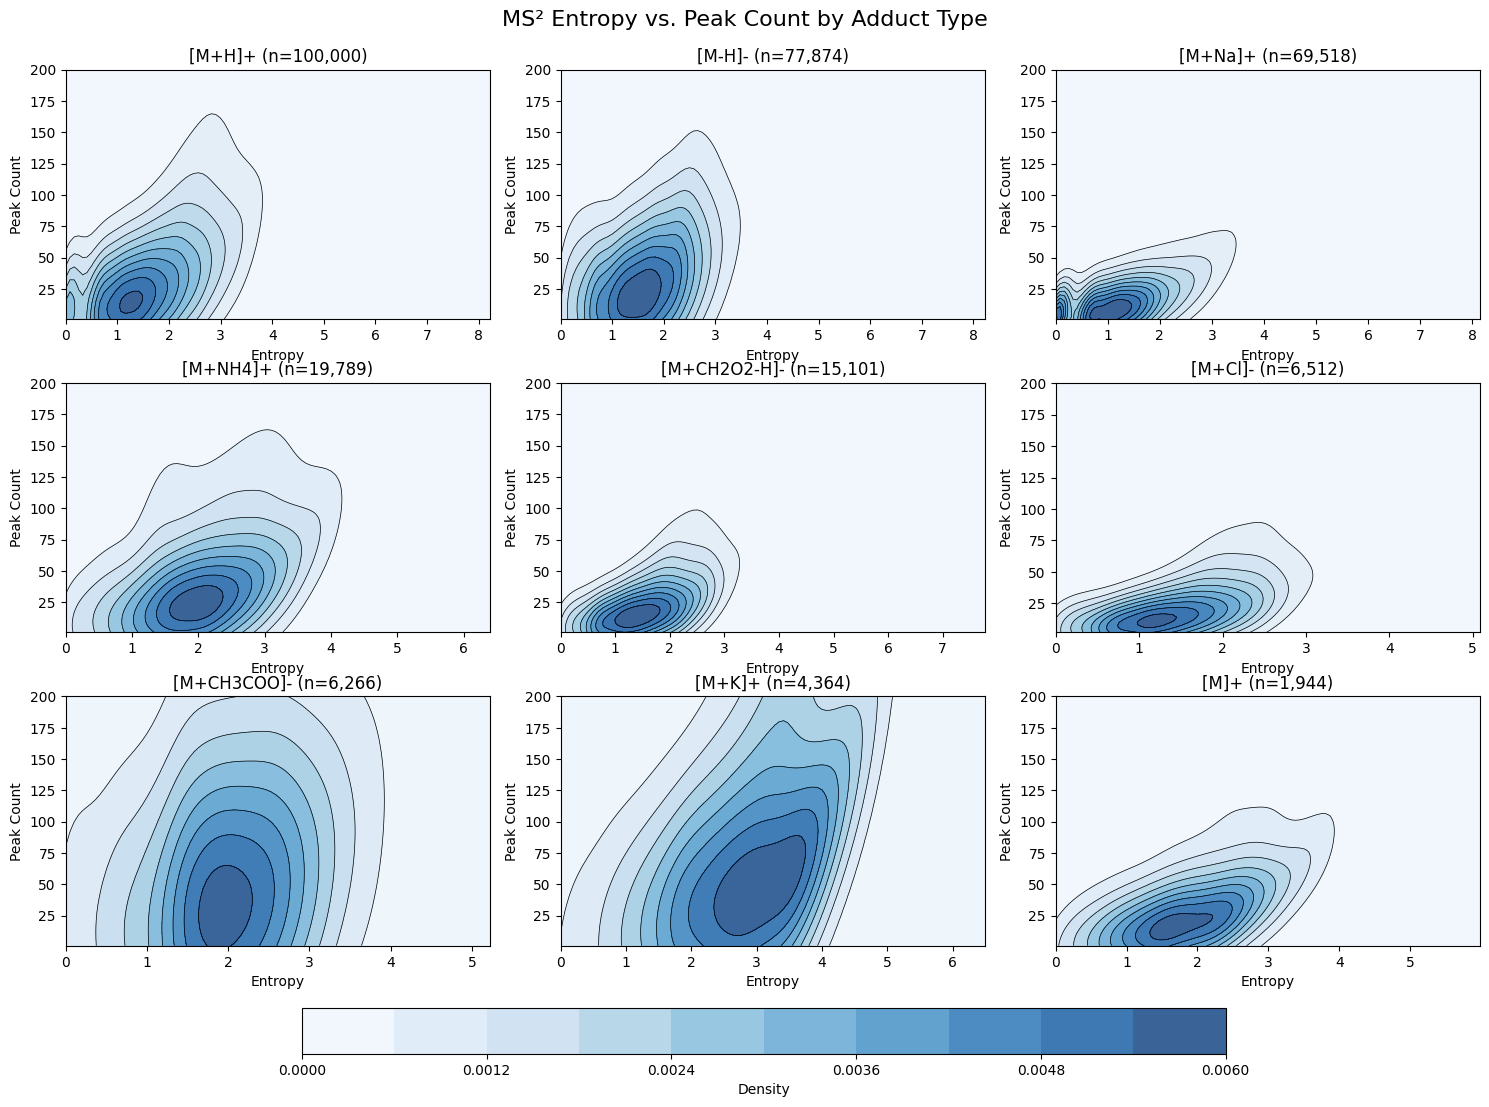

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

top_adducts = ['[M+H]+', '[M-H]-', '[M+Na]+', '[M+NH4]+', '[M+CH2O2-H]-', '[M+Cl]-', '[M+CH3COO]-', '[M+K]+', '[M]+']

contourf_handles = []

for i, adduct in enumerate(top_adducts):
    adduct_data = spectraverse_spec_df[spectraverse_spec_df['prec_type'] == adduct]
    sampled_df = adduct_data.sample(n=min(100_000, len(adduct_data)))
    entropy = sampled_df['ms_entropy'].values
    peak_num = sampled_df['num_peaks'].values

    if len(entropy) < 2:
        axes[i].text(0.5, 0.5, 'Insufficient Data', ha='center')
        axes[i].set_title(f'{adduct} (n={len(sampled_df)})')
        continue

    values = np.vstack([entropy, peak_num])
    kernel = gaussian_kde(values)

    x_min, x_max = entropy.min(), entropy.max()
    y_min, y_max = peak_num.min(), min(peak_num.max(), 200)
    X, Y = np.mgrid[x_min:x_max:100j, y_min:y_max:100j]
    positions = np.vstack([X.ravel(), Y.ravel()])
    Z = np.reshape(kernel(positions).T, X.shape)

    levels = 10
    cf = axes[i].contourf(X, Y, Z, levels=levels, cmap='Blues', alpha=0.8)
    axes[i].contour(X, Y, Z, levels=levels, colors='black', linewidths=0.5)
    axes[i].set_xlabel('Entropy')
    axes[i].set_ylabel('Peak Count')
    axes[i].set_title(f'{adduct} (n={len(sampled_df):,})')
    axes[i].set_ylim(y_min, y_max)
    contourf_handles.append(cf)

# Add a single colorbar for the last contourf plot
cbar = fig.colorbar(contourf_handles[-1], ax=axes, orientation='horizontal', fraction=0.05, pad=0.01)
cbar.set_label('Density')

plt.tight_layout()w
plt.subplots_adjust(top=0.93, bottom=0.2)  # Adjust bottom as needed
fig.suptitle('MS² Entropy vs. Peak Count by Adduct Type', fontsize=16)
plt.show()